<a href="https://colab.research.google.com/github/dldustj0715/machine_learning/blob/main/week10/%EC%A3%BC%EA%B0%80_lstm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 삼성전자 LSTM 주가 예측 — Window Size 변경
`WINDOW_SIZE` 값을 변경하여 과거 며칠의 시가로 다음 날 시가를 예측할지 설정합니다. 학습 데이터로만 정규화 기준을 산출하고, 테스트 구간 200일 전체를 평가합니다.

In [1]:
# Colab에서 패키지가 없다면 먼저 실행하세요.
%pip install finance-datareader tensorflow scikit-learn matplotlib pandas numpy

import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM

TEST_SIZE = 200
WINDOW_SIZE = 60  # 10, 30, 60, 90 등으로 변경 가능

samsung = fdr.DataReader('005930', '2016')
print(samsung.head())
print(samsung.shape)
print(samsung.tail())



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [finance-datareader]
             Open   High    Low  Close  Volume    Change
Date                                                    
2016-01-04  25200  25200  24100  24100  306939 -0.043651
2016-01-05  24040  24360  23720  24160  216002  0.002490
2016-01-06  24160  24160  23360  23500  366752 -0.027318
2016-01-07  23320  23660  23020  23260  282388 -0.010213
2016-01-08  23260  23720  23260  23420  257763  0.006879
(2660, 6)
              Open    High     Low   Close    Volume    Change
Date                                                          
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  194800  187000  194700   8729191  0.006202


In [2]:
openValues = samsung[['Open']]
print(openValues.head())

train_raw = openValues.iloc[:-TEST_SIZE]
test_raw = openValues.iloc[-TEST_SIZE:]

scaler = MinMaxScaler(feature_range=(0, 1))
train_data = scaler.fit_transform(train_raw)
test_data = scaler.transform(test_raw)

print("정규화 전:")
print(train_raw.head())

print("정규화 후:")
print(train_data[:5])



             Open
Date             
2016-01-04  25200
2016-01-05  24040
2016-01-06  24160
2016-01-07  23320
2016-01-08  23260
정규화 전:
             Open
Date             
2016-01-04  25200
2016-01-05  24040
2016-01-06  24160
2016-01-07  23320
2016-01-08  23260
정규화 후:
[[0.17560976]
 [0.16752613]
 [0.16836237]
 [0.16250871]
 [0.16209059]]


In [3]:
def make_sample(data, window):
    train, target = [], []
    for i in range(len(data) - window):
        train.append(data[i:i + window])
        target.append(data[i + window])
    return np.array(train), np.array(target)

X_train, y_train = make_sample(train_data, WINDOW_SIZE)
print('X_train:', X_train.shape, 'y_train:', y_train.shape)
print("첫 번째 입력 데이터:")
print(X_train[0])

print("첫 번째 정답 데이터:")
print(y_train[0])



X_train: (2400, 60, 1) y_train: (2400, 1)
첫 번째 입력 데이터:
[[0.17560976]
 [0.16752613]
 [0.16836237]
 [0.16250871]
 [0.16209059]
 [0.16111498]
 [0.16      ]
 [0.16069686]
 [0.15763066]
 [0.15888502]
 [0.15163763]
 [0.15721254]
 [0.16167247]
 [0.15790941]
 [0.15958188]
 [0.16334495]
 [0.16097561]
 [0.1569338 ]
 [0.16222997]
 [0.15888502]
 [0.16055749]
 [0.16181185]
 [0.16027875]
 [0.16027875]
 [0.16111498]
 [0.15581882]
 [0.15749129]
 [0.16083624]
 [0.16139373]
 [0.16432056]
 [0.16766551]
 [0.16543554]
 [0.16585366]
 [0.16432056]
 [0.16418118]
 [0.16334495]
 [0.16445993]
 [0.16432056]
 [0.16724739]
 [0.16905923]
 [0.17003484]
 [0.17003484]
 [0.17045296]
 [0.16557491]
 [0.16836237]
 [0.17073171]
 [0.17658537]
 [0.17491289]
 [0.17505226]
 [0.17630662]
 [0.17811847]
 [0.17756098]
 [0.17658537]
 [0.17686411]
 [0.17825784]
 [0.17881533]
 [0.1795122 ]
 [0.18034843]
 [0.1825784 ]
 [0.18202091]]
첫 번째 정답 데이터:
[0.1810453]


In [7]:
model = Sequential()
model.add(LSTM(16, input_shape=(WINDOW_SIZE, 1), activation='tanh', return_sequences=False))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, epochs=100, batch_size=16)

test_input = np.concatenate([train_data[-WINDOW_SIZE:], test_data], axis=0)
X_test, y_test = make_sample(test_input, WINDOW_SIZE)
pred = model.predict(X_test)
print("실제값:")
print(y_test[:10])

print("예측값:")
print(pred[:10])


Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0140
Epoch 2/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.5136e-04
Epoch 3/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.5326e-04
Epoch 4/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.2724e-04
Epoch 5/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.1816e-04
Epoch 6/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 4.1369e-04
Epoch 7/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 3.8840e-04
Epoch 8/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 3.8020e-04
Epoch 9/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 3.5392e-04
Epoch 10/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 3.4848e-04
Epoch 11/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.5226e-04
Epoch 12/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.4361e-04
Epoch 13/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.2360e-04
Epoch 14/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.1419e-04
Ep

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
실제값:
[[0.95470383]
 [0.96864111]
 [1.01254355]
 [1.02578397]
 [1.03484321]
 [0.98885017]
 [1.08013937]
 [1.07804878]
 [1.07944251]
 [1.04878049]]
예측값:
[[0.98480767]
 [0.96006066]
 [0.9711211 ]
 [1.0200437 ]
 [1.0384444 ]
 [1.0453968 ]
 [0.9940136 ]
 [1.0824898 ]
 [1.0940499 ]
 [1.0896764 ]]


In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 정규화된 데이터를 실제 주가(원)로 복원
y_test_real = scaler.inverse_transform(y_test)
pred_real = scaler.inverse_transform(pred)

# 평가 지표 계산
mae = mean_absolute_error(y_test_real, pred_real)
mse = mean_squared_error(y_test_real, pred_real)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_real, pred_real)

# 결과 출력
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MAE  : 12105.2605
MSE  : 267363048.2669
RMSE : 16351.2400
R²   : 0.9064


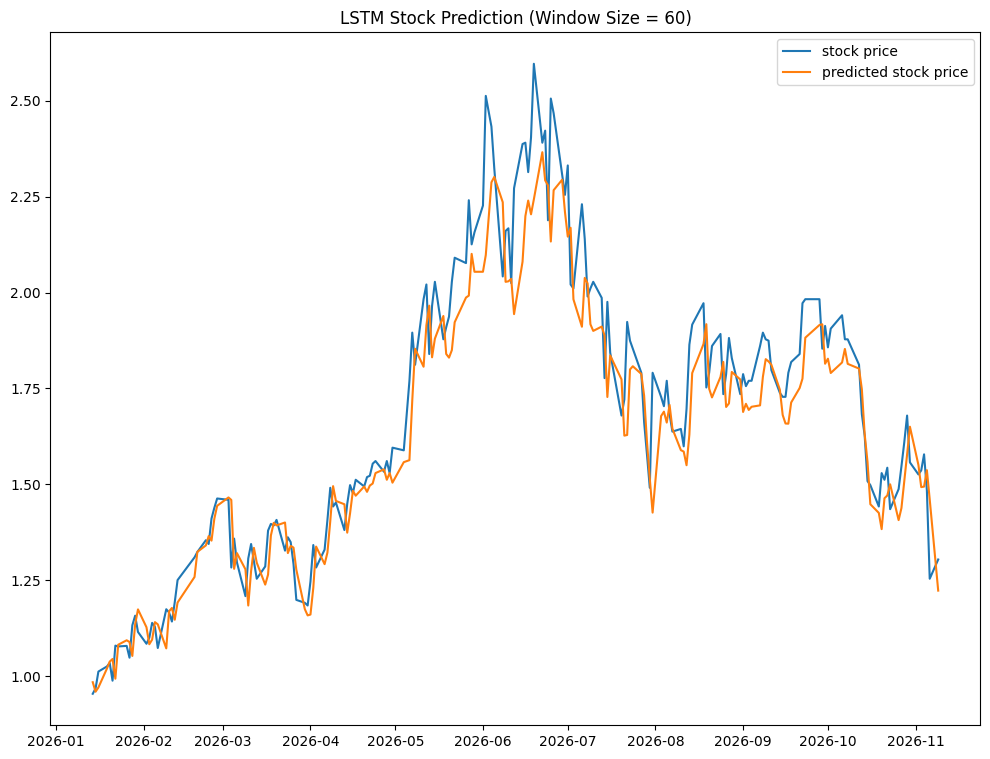

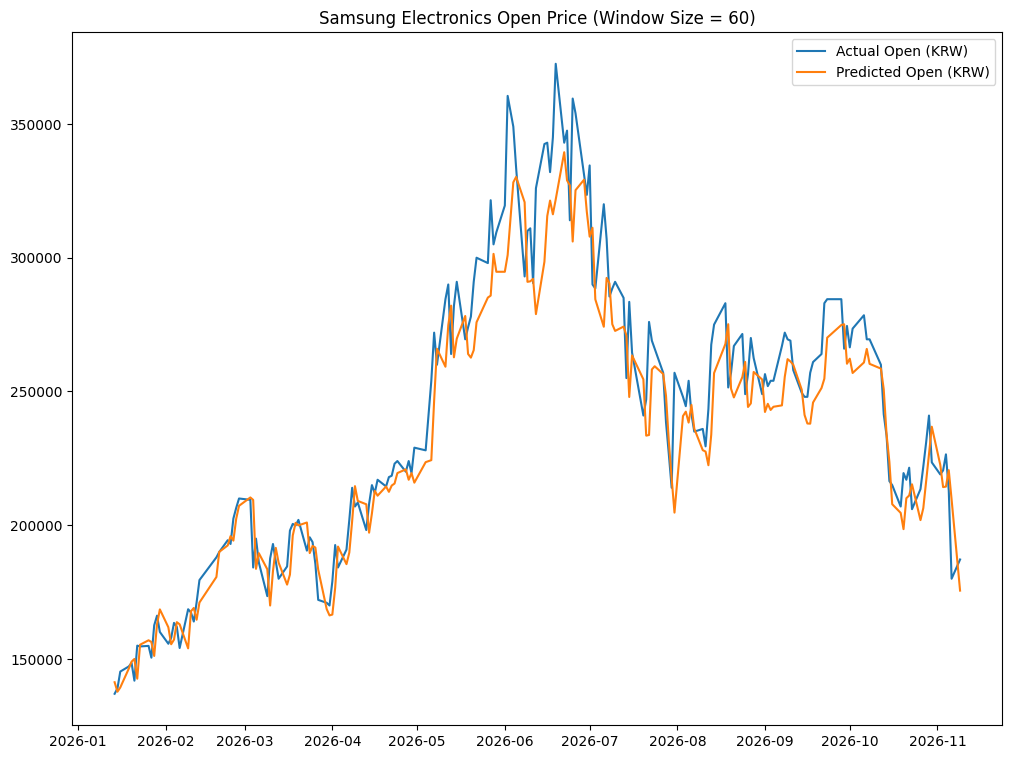

In [9]:
plt.figure(figsize=(12, 9))
plt.plot(test_raw.index, y_test.ravel(), label='stock price')
plt.plot(test_raw.index, pred.ravel(), label='predicted stock price')
plt.title(f'LSTM Stock Prediction (Window Size = {WINDOW_SIZE})')
plt.legend()
plt.show()

# 실제 원화 단위 그래프
real_price = scaler.inverse_transform(y_test)
pred_price = scaler.inverse_transform(pred)
plt.figure(figsize=(12, 9))
plt.plot(test_raw.index, real_price.ravel(), label='Actual Open (KRW)')
plt.plot(test_raw.index, pred_price.ravel(), label='Predicted Open (KRW)')
plt.title(f'Samsung Electronics Open Price (Window Size = {WINDOW_SIZE})')
plt.legend()
plt.show()